In [1]:
import sys

sys.path.append("../src")

import os
import numpy as np
import jax.numpy as jnp
from jax import random

import torch
from torch import optim

from sklearn.metrics import mean_squared_error

import matplotlib.pyplot as plt
import pandas as pd

from data_processing.load import (
    load_and_preprocess_data,
    load_and_preprocess_forecast_data,
)
from data_processing.utils import (
    load_checkpoint,
    save_scaler_params,
    save_torch_checkpoint,
    load_torch_model,
    QuantileDistribution,
)
from models.model import WindPowerQuantile, model_mw_gamma, WindPowerQuantileEnsembles

from numpyro.infer import Predictive
import arviz as az
from operator import itemgetter

In [2]:
# import importlib
# import models.model as load_models

# importlib.reload(load_models)
# from models.model import WindPowerQuantile, model_mw_gamma, WindPowerQuantileEnsembles

### Load data and preprocess

- wind direction transformed from degree using sin and cos
- select one bid zone
- include UMM downtime data
- calculate capacity factor
- scale input features and meta data

Shapes:

- X: (timestamps, wind parks, features)
- Y: (timestamps)
- sites_meta: (wind parks, 1)


In [3]:
bid_zone = "ELSPOT NO1"
dataset = "forecast"

In [4]:
# Load nowcast data
data_nowcast = load_and_preprocess_data(bid_zone=bid_zone)
# Load forecast data
data_forecast = load_and_preprocess_forecast_data(
    bid_zone=bid_zone,
)

Loading data for ELSPOT NO1...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Preprocessing done. X_train shape: (19130, 6, 10)
Preprocessing done. X_test shape: (2160, 6, 10)
Loading forecast data for ELSPOT NO1, ensemble members [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]...
RangeIndex(start=0, stop=6874212, step=1)
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=6874212, step=1)
Before 2-day ahead filtering: 438126 rows
After 2-day ahead filtering: 164124 rows
Lead time range: 34.0h to 61.0h


... (3 outputs left out)

QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Preprocessing done. X_train shape: (18141, 6, 15, 11)
Preprocessing done. X_test shape: (1881, 6, 15, 11)


In [5]:
if dataset == "nowcast":
    (
        X_train,
        X_test,
        Y_train_gen,
        Y_test_gen,
        Y_train_cf,
        Y_test_cf,
        Y_train_aval,
        Y_test_aval,
        sites_meta,
        feature_cols,
    ) = itemgetter(
        "X_train",
        "X_test",
        "Y_train_gen",
        "Y_test_gen",
        "Y_train_cf",
        "Y_test_cf",
        "Y_train_aval",
        "Y_test_aval",
        "sites_meta",
        "feature_cols",
    )(
        data_nowcast
    )
elif dataset == "forecast":
    (
        X_train,
        X_test,
        Y_train_gen,
        Y_test_gen,
        Y_train_cf,
        Y_test_cf,
        Y_train_aval,
        Y_test_aval,
        sites_meta,
        feature_cols,
    ) = itemgetter(
        "X_train",
        "X_test",
        "Y_train_gen",
        "Y_test_gen",
        "Y_train_cf",
        "Y_test_cf",
        "Y_train_aval",
        "Y_test_aval",
        "sites_meta",
        "feature_cols",
    )(
        data_forecast
    )
else:
    raise KeyError(f"{dataset} is not a valid dataset, must be forecast or nowcast")

In [6]:
# Save scaler params ONCE (reused by all models for this bid zone)
save_scaler_params(
    scaler_params=data_nowcast["scaler_params"],
    site_scaler_params=data_nowcast["site_scaler_params"],
    bid_zone=bid_zone,
    split_time=pd.Timestamp("2025-01-01 00:00:00", tz="CET"),
    dataset="nowcast",
    dir_path="../checkpoints",
)
save_scaler_params(
    scaler_params=data_forecast["scaler_params"],
    site_scaler_params=data_forecast["site_scaler_params"],
    bid_zone=bid_zone,
    split_time=pd.Timestamp("2025-01-01 00:00:00", tz="CET"),
    dataset="forecast",
    dir_path="../checkpoints",
)

Saved scaler parameters for ELSPOT NO1: ../checkpoints/scaler_params_ELSPOT_NO1_nowcast.pkl
Saved scaler parameters for ELSPOT NO1: ../checkpoints/scaler_params_ELSPOT_NO1_forecast.pkl


'../checkpoints/scaler_params_ELSPOT_NO1_forecast.pkl'

### Deterministic Quantile NN

- Shared weights for all parks -> sum over parks
- Predicts Quantiles to approximate the full CDF
- Median acts as an anchor
- Distances to median for other quantiles
- All distances are generated cumulative by softplus -> positive -> ordering guaranteed and no crossing


In [7]:
X_train_tensor = torch.tensor(X_train)
Y_train_cf_tensor = torch.tensor(Y_train_cf)
Y_train_gen_tensor = torch.tensor(Y_train_gen)
X_test_tensor = torch.tensor(X_test)
Y_test_cf_tensor = torch.tensor(Y_test_cf)
Y_test_gen_tensor = torch.tensor(Y_test_gen)
Y_test_aval_tensor = torch.tensor(Y_test_aval)
sites_meta_tensor = torch.tensor(sites_meta, dtype=torch.float32)

In [8]:
def quantile_loss(preds, target, quantiles=(0.025, 0.5, 0.975)):
    # preds: [T, Q], target: [T]
    diff = target.unsqueeze(-1) - preds  # [T, Q]
    quantiles = torch.tensor(quantiles).to(preds.device)  # [Q]

    # Pinball loss:
    loss = torch.maximum(quantiles * diff, (quantiles - 1) * diff)
    return torch.mean(torch.mean(loss, dim=1))  # TODO sum or mean??


def quantile_loss_weighted(preds, target, quantiles):
    diff = target.unsqueeze(-1) - preds  # [T, Q]
    quantiles = torch.tensor(quantiles, dtype=preds.dtype, device=preds.device)  # [Q]

    # Pinball loss for each quantile
    loss_q = torch.maximum(quantiles * diff, (quantiles - 1) * diff)  # [T, Q]

    # Normalize weights to sum to 1
    weights = torch.sqrt(quantiles * (1 - quantiles))
    weights = weights / weights.sum()

    # Weighted average over quantiles
    weighted_loss = (loss_q * weights).mean()

    return weighted_loss


def phys_penalty(q, lam=1):
    return lam * torch.mean(torch.relu(-q) ** 2)

In [9]:
def train_quantile_model(
    model,
    optimizer,
    criterion,
    X,
    Y,
    num_steps,
    log_every=250,
):
    losses = []

    for step in range(num_steps):
        model.train()
        optimizer.zero_grad()

        y_pred = model(X)
        loss = criterion(y_pred, Y)
        losses.append(loss.item())

        loss.backward()
        optimizer.step()

        if step % log_every == 0:
            print(f"Step {step:3d} | Loss: {loss.item():.4f}")

    return losses


def evaluate_quantile_model_rmse(
    model,
    X_test,
    Y_test,
    quantiles,
    quantile_value=0.5,
):
    # find quantile index
    q_idx = np.where(quantiles == quantile_value)[0]
    if len(q_idx) == 0:
        raise ValueError(f"Quantile {quantile_value} not found in quantiles.")
    q_idx = q_idx[0]

    model.eval()
    with torch.no_grad():
        y_pred = model(X_test)

    Y_pred = y_pred.cpu().numpy()
    mse = mean_squared_error(Y_test, Y_pred[:, q_idx])
    rmse = float(np.sqrt(mse))

    return Y_pred, rmse

In [10]:
# Ensemble model: uses the different ensemble members
quantiles = np.linspace(0, 1, 51)
target = "gen"

_, num_windparks, num_ensembles, num_features = X_train_tensor.shape
nn_model_quantile_ensemble = WindPowerQuantileEnsembles(
    num_features, quantiles, target=target
)

optimizer = optim.Adam(nn_model_quantile_ensemble.parameters(), lr=1e-3)
criterion = lambda preds, target: quantile_loss_weighted(
    preds, target, quantiles=quantiles
)

losses_ensemble = train_quantile_model(
    model=nn_model_quantile_ensemble,
    optimizer=optimizer,
    criterion=criterion,
    X=X_train_tensor,
    Y=Y_train_gen_tensor,
    num_steps=3000,
)

checkpoint_path = save_torch_checkpoint(
    model=nn_model_quantile_ensemble,
    optimizer=optimizer,
    model_name="WindPowerQuantileEnsembles",
    bid_zone=bid_zone,
    quantiles=quantiles,
    num_features=num_features,
    dataset=dataset,
    target=target,
)


Y_pred_ensembles, rmse_ensembles = evaluate_quantile_model_rmse(
    model=nn_model_quantile_ensemble,
    X_test=X_test_tensor,
    Y_test=Y_test_gen,
    quantiles=quantiles,
    quantile_value=0.5,
)

print("Evaluation metrics:")
print(f"RMSE: {rmse_ensembles:.2f} MW")

Step   0 | Loss: 0.9827
Step 250 | Loss: 0.4658
Step 500 | Loss: 0.3750
Step 750 | Loss: 0.3545
Step 1000 | Loss: 0.3493
Step 1250 | Loss: 0.3459
Step 1500 | Loss: 0.3423
Step 1750 | Loss: 0.3385
Step 2000 | Loss: 0.3340
Step 2250 | Loss: 0.3300
Step 2500 | Loss: 0.3265
Step 2750 | Loss: 0.3238
Saved checkpoint: WindPowerQuantileEnsembles_2025-12-17_15-51-30_forecast_gen_ELSPOT_NO1.pt
Evaluation metrics:
RMSE: 72.99 MW


In [11]:
# Model: only uses first ensemble member (+ variance)
quantiles = np.linspace(0, 1, 51)
target = "gen"

_, num_windparks, num_features = X_train_tensor[:, :, 0].shape
nn_model_quantile = WindPowerQuantile(num_features, quantiles, target=target)

optimizer = optim.Adam(nn_model_quantile.parameters(), lr=1e-3)
criterion = lambda preds, target: quantile_loss_weighted(
    preds, target, quantiles=quantiles
)

losses_single = train_quantile_model(
    model=nn_model_quantile,
    optimizer=optimizer,
    criterion=criterion,
    X=X_train_tensor[:, :, 0],  # first ensemble member
    Y=Y_train_gen_tensor,
    num_steps=3000,
)

checkpoint_path = save_torch_checkpoint(
    model=nn_model_quantile,
    optimizer=optimizer,
    model_name="WindPowerQuantile",
    bid_zone=bid_zone,
    quantiles=quantiles,
    num_features=num_features,
    dataset=dataset,
    target=target,
)

Y_pred_single, rmse_single = evaluate_quantile_model_rmse(
    model=nn_model_quantile,
    X_test=X_test_tensor[:, :, 0],
    Y_test=Y_test_gen,
    quantiles=quantiles,
    quantile_value=0.5,
)

print("Evaluation metrics:")
print(f"RMSE: {rmse_single:.2f} MW")

Step   0 | Loss: 0.9927
Step 250 | Loss: 0.4253
Step 500 | Loss: 0.3513
Step 750 | Loss: 0.3280
Step 1000 | Loss: 0.3134
Step 1250 | Loss: 0.3059
Step 1500 | Loss: 0.3010
Step 1750 | Loss: 0.2977
Step 2000 | Loss: 0.2949
Step 2250 | Loss: 0.2926
Step 2500 | Loss: 0.2908
Step 2750 | Loss: 0.2892
Saved checkpoint: WindPowerQuantile_2025-12-17_15-54-01_forecast_gen_ELSPOT_NO1.pt
Evaluation metrics:
RMSE: 73.68 MW


### Load checkpoint


In [12]:
# loaded_model, checkpoint_data = load_torch_model(
#     file_name="WindPowerQuantile_2025-12-03_14-57-43_now_gen_ELSPOT_NO1",
# )

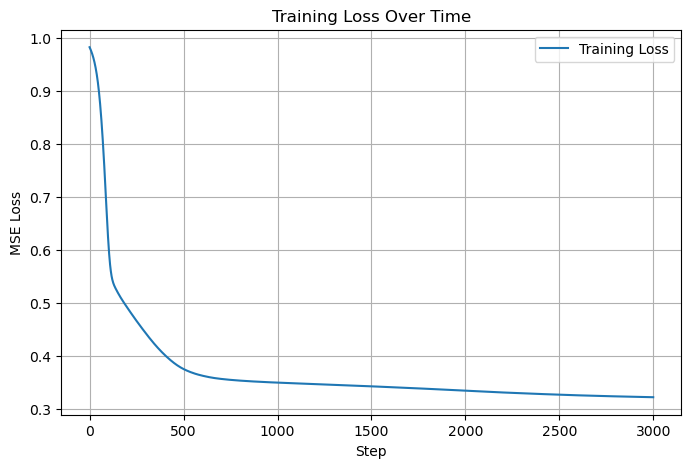

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(losses_ensemble, label="Training Loss")
plt.xlabel("Step")
plt.ylabel("MSE Loss")
plt.title("Training Loss Over Time")
plt.legend()
plt.grid(True)
plt.show()

In [15]:
q02_idx = (quantiles == 0.02).nonzero()[0].item()
q98_idx = (quantiles == 0.98).nonzero()[0].item()
avg_ci_width = np.mean((Y_pred_ensembles[:, q98_idx] - Y_pred_ensembles[:, q02_idx]))
print(f"Average 96% CI width: {avg_ci_width}")

Average 96% CI width: 234.2629852294922


In [16]:
def plot_qr_hdi_prediction(
    Y_true,
    conf_interval,
    medians,
    n_plot=1000,
    cred_mass=0.95,
    title="QR Power Generation Prediction",
):
    fig, axes = plt.subplots(
        nrows=2,
        figsize=(10, 8),
        sharex=True,
        constrained_layout=True,
    )

    # Top plot
    ax = axes[0]
    ax.plot(
        Y_true[:n_plot],
        ".",
        color="black",
        label="Observed data",
        markersize=4,
    )

    ax.fill_between(
        np.arange(n_plot),
        conf_interval[:n_plot, 0],
        conf_interval[:n_plot, 1],
        color="#A6CEE3",
        alpha=0.5,
        label=f"{int(cred_mass * 100)}% credible interval",
    )

    ax.plot(
        medians[:n_plot],
        color="red",
        label="Posterior median",
        lw=2,
    )

    ax.set(
        ylabel="Total power",
        title=title,
    )
    ax.legend()

    # Bottom panel
    width = conf_interval[:n_plot, 1] - conf_interval[:n_plot, 0]
    ax2 = axes[1]
    ax2.plot(width, color="#A6CEE3")
    ax2.set(
        xlabel="Time index",
        ylabel="Interval width",
        title=f"{int(cred_mass * 100)}% Credible Interval Width",
    )

    return fig, axes


def extract_quantile_curves(
    Y_pred_quantiles,
    quantiles,
    median_q=0.5,
    lower_q=0.02,
    upper_q=0.98,
):
    def q_idx(q):
        idx = np.where(quantiles == q)[0]
        if len(idx) == 0:
            raise ValueError(f"Quantile {q} not found in quantiles.")
        return idx[0]

    median_idx = q_idx(median_q)
    lower_idx = q_idx(lower_q)
    upper_idx = q_idx(upper_q)

    median = Y_pred_quantiles[:, median_idx]
    lower = Y_pred_quantiles[:, lower_idx]
    upper = Y_pred_quantiles[:, upper_idx]

    return median, lower, upper

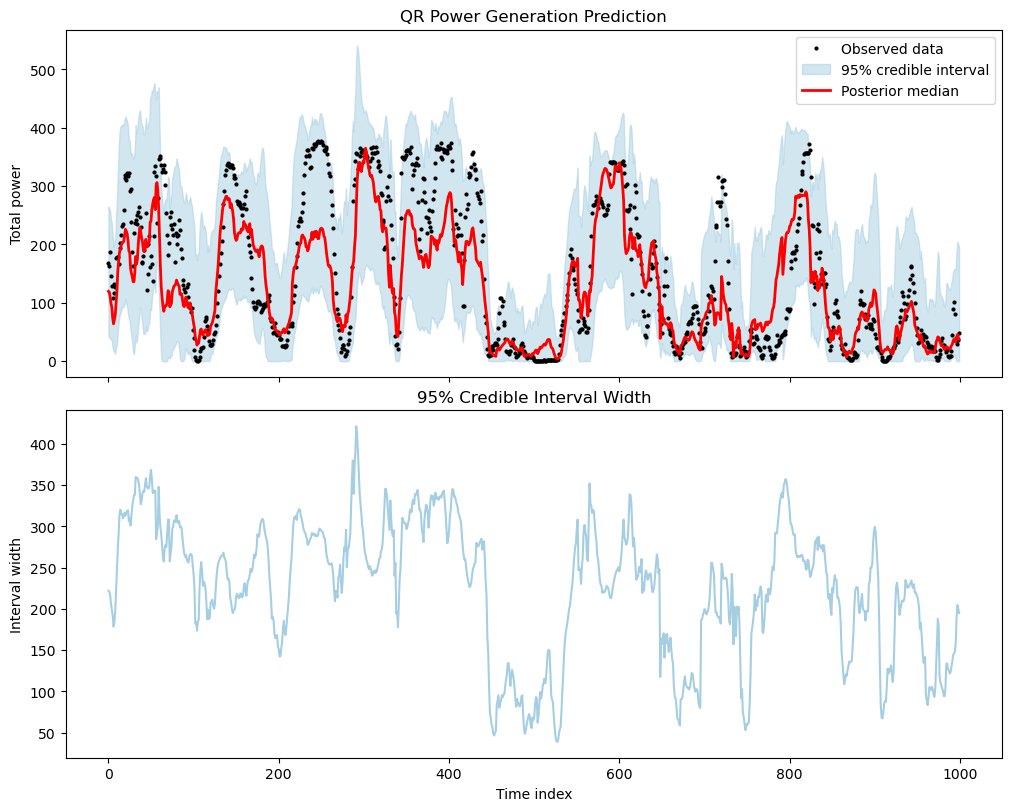

In [17]:
median, lower, upper = extract_quantile_curves(
    Y_pred_quantiles=Y_pred_ensembles,
    quantiles=quantiles,
    median_q=0.5,
    lower_q=0.02,
    upper_q=0.98,
)

fig, axes = plot_qr_hdi_prediction(
    Y_true=Y_test_gen,
    conf_interval=np.column_stack([lower, upper]),
    medians=median,
    n_plot=1000,
)

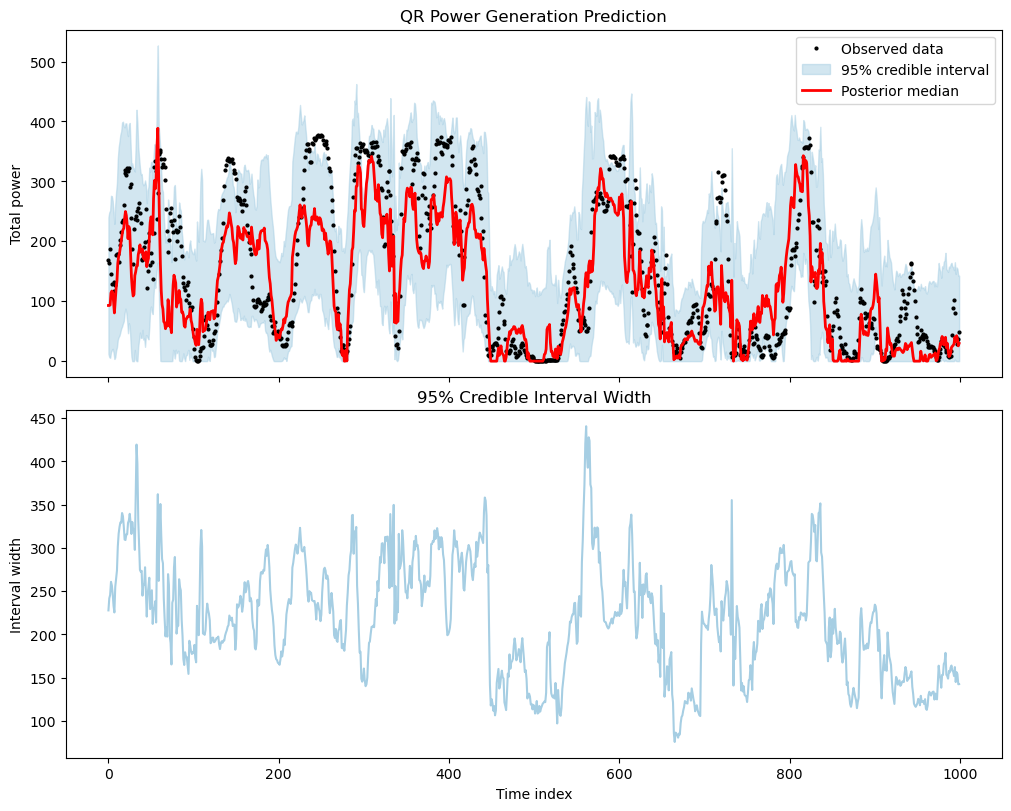

In [18]:
median, lower, upper = extract_quantile_curves(
    Y_pred_quantiles=Y_pred_single,
    quantiles=quantiles,
    median_q=0.5,
    lower_q=0.02,
    upper_q=0.98,
)

fig, axes = plot_qr_hdi_prediction(
    Y_true=Y_test_gen,
    conf_interval=np.column_stack([lower, upper]),
    medians=median,
    n_plot=1000,
)

### Sanity checks


In [19]:
def plot_quantile_calibration(
    Y_true,
    Y_pred_quantiles,
    quantiles,
    title="Calibration plot (quantile reliability)",
):
    # empirical coverage: P(Y <= Q_tau)
    emp_cov = [np.mean(Y_true <= Y_pred_quantiles[:, i]) for i in range(len(quantiles))]

    plt.figure(figsize=(6, 6))
    plt.plot(quantiles, emp_cov, "o-", label="Empirical")
    plt.plot([0, 1], [0, 1], "--", color="gray", label="Ideal")
    plt.xlabel("Nominal quantile τ")
    plt.ylabel("Empirical coverage")
    plt.title(title)
    plt.legend()
    plt.grid(True)

    return np.array(emp_cov)

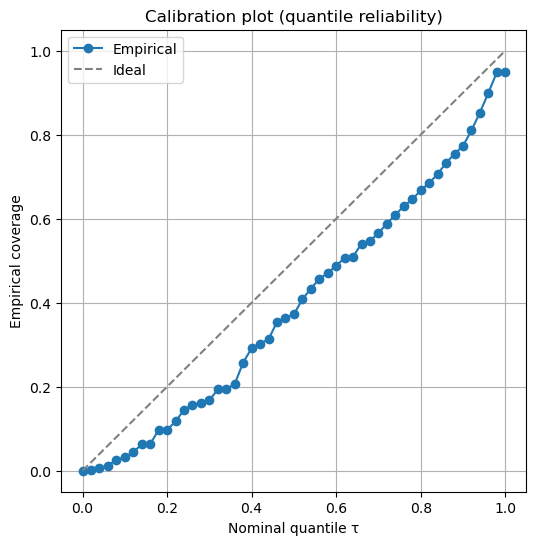

In [20]:
emp_cov = plot_quantile_calibration(
    Y_true=Y_test_gen,
    Y_pred_quantiles=Y_pred_ensembles,
    quantiles=quantiles,
)

plt.show()

### SAGE (feature importance)

Ensemble model:

- feature
- ensemble
- feature and ensemble

Quantile Regression:


In [21]:
# X_*_tensor: [T, W, M, F]
X_train_flat = X_train_tensor.reshape(X_train_tensor.shape[0], -1).numpy()
X_test_flat = X_test_tensor.reshape(X_test_tensor.shape[0], -1).numpy()

In [22]:
def build_global_feature_groups(W, M, F, feature_cols):
    groups = []
    group_names = []

    n_blocks = W * M  # number of (w,m) blocks

    for f, name in enumerate(feature_cols):
        idxs = [f + k * F for k in range(n_blocks)]
        groups.append(idxs)
        group_names.append(name)

    return groups, group_names


def build_ensemble_member_groups(W, M, F):
    groups = []
    group_names = []

    for m in range(M):
        idxs = []
        for w in range(W):
            block_start = (w * M + m) * F
            idxs.extend(range(block_start, block_start + F))
        groups.append(idxs)
        group_names.append(f"ensemble_{m}")

    return groups, group_names


def build_feature_ensemble_groups(W, M, F, feature_cols):
    groups = []
    group_names = []

    for m in range(M):
        for f, fname in enumerate(feature_cols):
            idxs = []
            for w in range(W):
                flat_idx = ((w * M + m) * F) + f
                idxs.append(flat_idx)

            groups.append(idxs)
            group_names.append(f"ens_{m}__{fname}")

    return groups, group_names


class SageQuantileWrapper:
    def __init__(self, torch_model, W, M, F, q_idx):
        self.model = torch_model.eval()
        self.W, self.M, self.F = W, M, F
        self.q_idx = q_idx

    def __call__(self, X_flat):
        X = torch.from_numpy(X_flat).view(-1, self.W, self.M, self.F)
        with torch.no_grad():
            preds = self.model(X)
        return preds[:, self.q_idx].numpy()

In [26]:
T, W, M, F = X_train_tensor.shape
groups_features, group_names_features = build_global_feature_groups(
    W, M, F, feature_cols
)
groups_ensembles, group_names_ensembles = build_ensemble_member_groups(W, M, F)
groups_features_ensembles, group_names_features_ensembles = (
    build_feature_ensemble_groups(W, M, F, feature_cols)
)

wrapped_model_median = SageQuantileWrapper(
    nn_model_quantile_ensemble,
    W,
    M,
    F,
    (quantiles == 0.5).nonzero()[0].item(),
)
wrapped_model_q02 = SageQuantileWrapper(
    nn_model_quantile_ensemble,
    W,
    M,
    F,
    (quantiles == 0.02).nonzero()[0].item(),
)
wrapped_model_q98 = SageQuantileWrapper(
    nn_model_quantile_ensemble,
    W,
    M,
    F,
    (quantiles == 0.98).nonzero()[0].item(),
)

In [27]:
import sage


X_bg = X_train_flat[:1024]


def apply_sage(model, X_bg, groups, X_test, Y_test, n_permutations=128):

    imputer = sage.GroupedMarginalImputer(model, X_bg, groups)
    estimator = sage.PermutationEstimator(imputer, loss="mse")  # median MSE
    sage_values = estimator(
        X_test,
        Y_test,
        n_permutations=n_permutations,
    )
    return sage_values


sage_values_features = apply_sage(
    wrapped_model_median, X_bg, groups_features, X_test_flat, Y_test_gen
)
sage_values_ensembles = apply_sage(
    wrapped_model_median, X_bg, groups_ensembles, X_test_flat, Y_test_gen
)
sage_values_features_ensembles = apply_sage(
    wrapped_model_median, X_bg, groups_features_ensembles, X_test_flat, Y_test_gen
)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

/opt/homebrew/Caskroom/miniconda/base/envs/masters/lib/python3.12/site-packages/sage/plotting.py:75: Warning: Plotting 165 features may make figure too crowded, consider using max_features
  warnings.warn('Plotting {} features may make figure too crowded, '


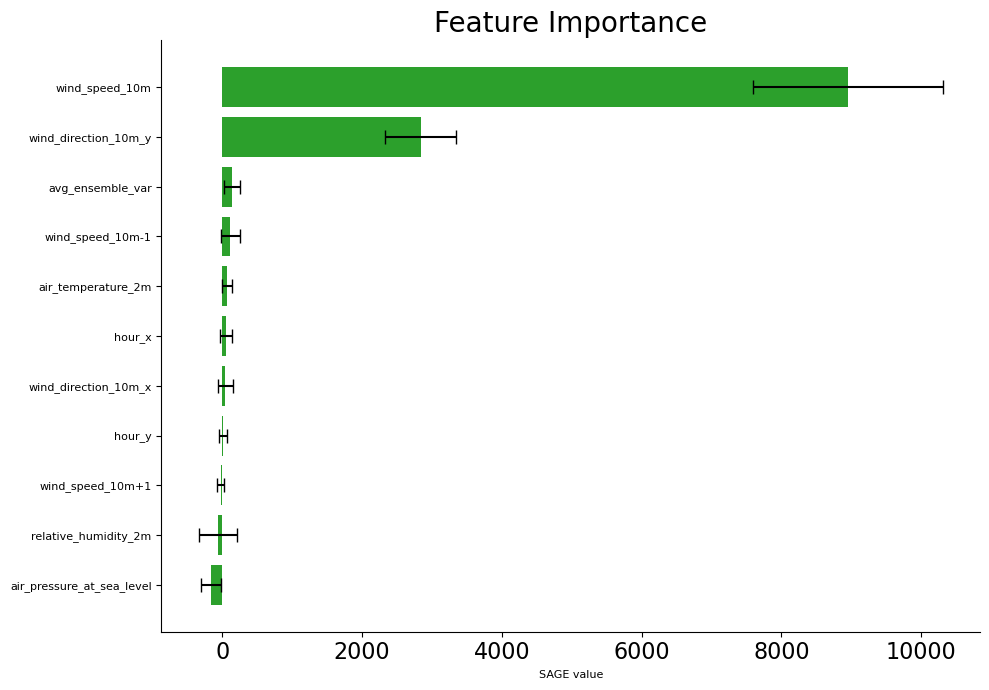

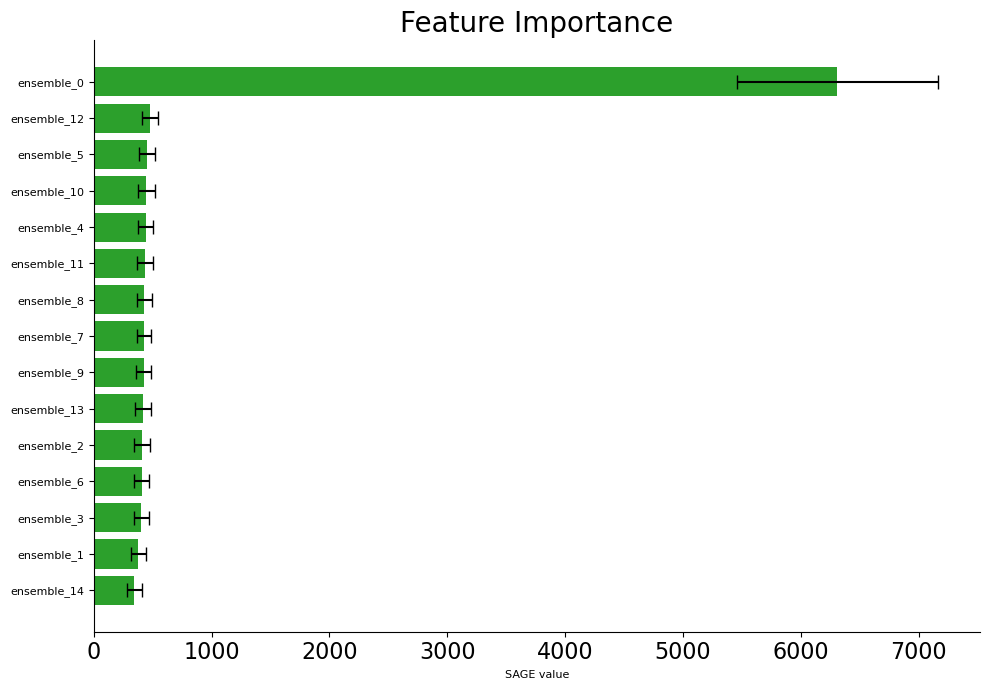

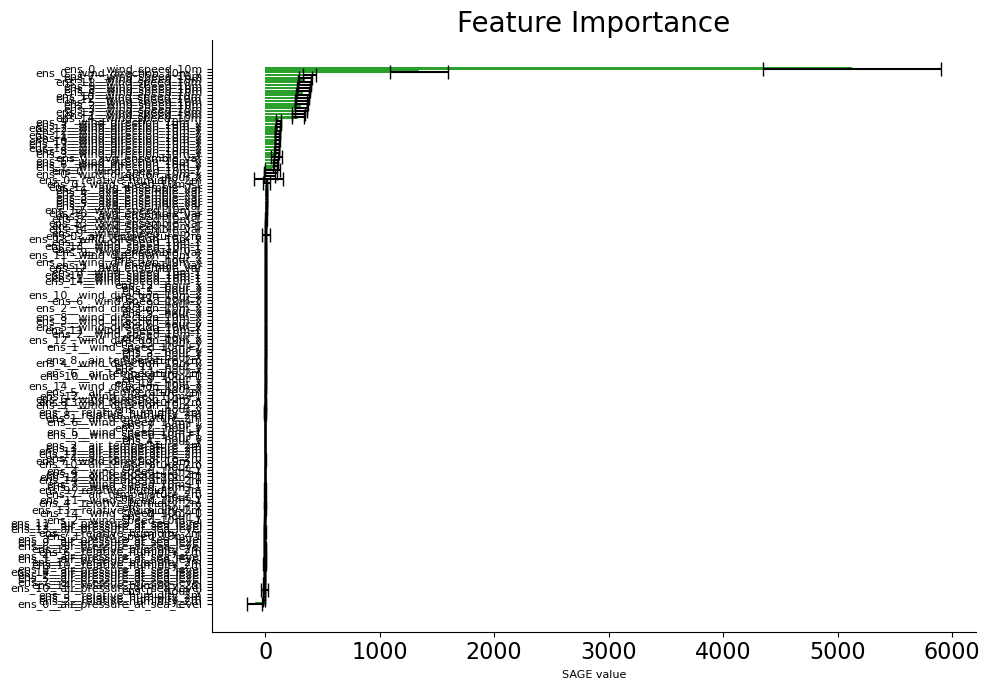

In [28]:
sage_values_features.plot(group_names_features, label_size=8)
sage_values_ensembles.plot(group_names_ensembles, label_size=8)
sage_values_features_ensembles.plot(group_names_features_ensembles, label_size=8)

In [ ]:
sage_values_by_tau = {}
for q_idx, tau in enumerate(quantiles[::10]):  # only every 10th quantile
    wrapped_model = SageQuantileWrapper(nn_model_quantile, W, M, F, q_idx)
    sage_values_by_tau[tau] = apply_sage(
        wrapped_model, X_bg, groups_features, X_test_flat, Y_test_gen
    )

In [ ]:
values_mean = np.stack(
    [sage_values_by_tau[tau].values for tau in quantiles], axis=0
)  # [Q, n_groups]
values_std = np.stack([sage_values_by_tau[tau].std for tau in quantiles], axis=0)

sage_mean = values_mean.mean(axis=0)
sage_std = values_std.mean(axis=0)

In [ ]:
idx = np.argsort(sage_mean)

plt.figure(figsize=(10, 6))
plt.barh(
    np.array(group_names_features)[idx],
    sage_mean[idx],
    xerr=sage_std[idx],
    capsize=3,
    color="green",
)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Average SAGE value (MSE)")
plt.title("Average SAGE Feature Importance across Quantiles")
plt.tight_layout()
plt.show()

In [ ]:
sage_values_features.plot(group_names_features)
sage_values_by_tau[0.02].plot(group_names_features)
sage_values_by_tau[0.98].plot(group_names_features)
# sage_values_ensembles.plot(group_names_ensembles)
# sage_values_features_ensembles.plot(group_names_features_ensembles, label_size=8)

### Approximation of CDF and PDF

- with enough quantiles, the CDF can be approximated empirically


In [29]:
def compute_qr_intervals(
    Y_pred,
    taus,
    cred_mass=0.95,
    n_samples=5000,
):
    T = Y_pred.shape[0]

    hdis = np.empty((T, 2))
    medians = np.empty(T)
    q_lower = np.empty(T)
    q_upper = np.empty(T)

    for i in range(T):
        qd = QuantileDistribution(taus, Y_pred[i])
        hdis[i] = qd.hdi(cred_mass=cred_mass, n_samples=n_samples)
        medians[i] = qd.icdf(0.5)
        q_lower[i] = qd.icdf((1 - cred_mass) / 2)
        q_upper[i] = qd.icdf(1 - (1 - cred_mass) / 2)

    return hdis, medians, q_lower, q_upper

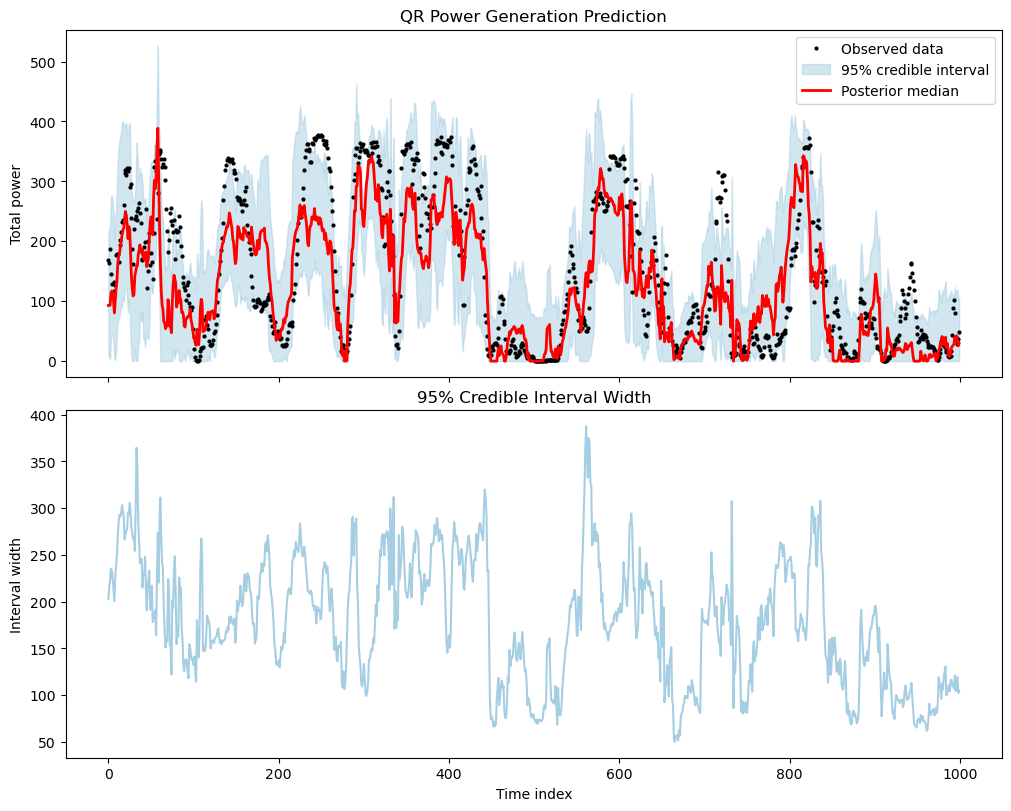

In [31]:
taus = np.linspace(0, 1, 51)

conf_interval, medians, q025_qr, q975_qr = compute_qr_intervals(
    Y_pred=Y_pred_single,
    taus=taus,
    cred_mass=0.95,
)

fig, axes = plot_qr_hdi_prediction(
    Y_true=Y_test_gen,
    conf_interval=conf_interval,
    medians=medians,
    n_plot=1000,
)

plt.show()

### Load BNN to compare Quantiles


In [ ]:
loaded_model, checkpoint_data = load_torch_model(
    file_name="WindPowerQuantile_2025-12-10_12-29-26_foreast_gen_ELSPOT_NO1",
    dir_path="../checkpoints",
)

In [ ]:
state_ckp = load_checkpoint(
    file_name="model_mw_gamma_2025-12-10_11-32-23_forecast_ELSPOT_NO1"
)
samples_gamma = state_ckp["samples"]
args = state_ckp["args"]
rng_key_ckp = state_ckp["rng_key"]
rng_key, rng_key_predict = random.split(rng_key_ckp)

predictive = Predictive(model_mw_gamma, samples_gamma)(rng_key_predict, X_test)

preds = predictive["Y"]
mu = predictive["mu"]
alpha = predictive["alpha"]

preds_mean = preds.mean(axis=0)
median_bnn = np.percentile(preds, 50, axis=0)
q025_bnn = np.percentile(preds, 2.5, axis=0)
q975_bnn = np.percentile(preds, 97.5, axis=0)
hdi_bnn = az.hdi(np.expand_dims(preds, axis=0), hdi_prob=0.95)

q_bnn = np.array([])

In [ ]:
# HDI CI
n_plot = 530

fig, axes = plt.subplots(nrows=2, figsize=(15, 8), sharex=True, constrained_layout=True)

ax = axes[0]
ax.plot(Y_test_gen[:n_plot], ".", color="black", label="Observed data", markersize=4)

ax.fill_between(
    np.arange(n_plot),
    conf_interval[:n_plot, 0],
    conf_interval[:n_plot, 1],
    color="red",
    alpha=0.25,
    label="95% credible interval QR",
)

ax.plot(medians[:n_plot], color="red", label="Posterior median", lw=2)

ax.set(
    ylabel="Total power",
    title="BNN Power Generation Prediction",
)
ax.legend()

ax.fill_between(
    np.arange(n_plot),
    hdi_bnn[:n_plot, 0],
    hdi_bnn[:n_plot, 1],
    color="blue",
    alpha=0.25,
    label="95% credible interval BNN",
)

ax.plot(median_bnn[:n_plot], color="blue", label="Posterior median BNN", lw=2)

ax.set(
    ylabel="Total power",
    title="BNN Power Generation Prediction",
)
ax.legend()

normalization_factor = np.median(Y_test_gen)
# Compute interval width
width = conf_interval[:n_plot, 1] - conf_interval[:n_plot, 0]
width_bnn = hdi_bnn[:n_plot, 1] - hdi_bnn[:n_plot, 0]
ax2 = axes[1]
ax2.plot(width / normalization_factor, color="red", label="HDI width QR")
ax2.plot(width_bnn / normalization_factor, color="blue", label="HDI width BNN")
ax2.set(
    xlabel="Time index",
    ylabel="Interval width",
    title="95% Credible Interval Width",
)
ax2.legend()


plt.show()

In [ ]:
# CI based on quantiles
n_plot = 530

fig, axes = plt.subplots(nrows=2, figsize=(15, 8), sharex=True, constrained_layout=True)

ax = axes[0]
ax.plot(Y_test_gen[:n_plot], ".", color="black", label="Observed data", markersize=4)

ax.fill_between(
    np.arange(n_plot),
    q025_qr[:n_plot],
    q975_qr[:n_plot],
    color="red",
    alpha=0.25,
    label="95% credible interval QR",
)

ax.plot(medians[:n_plot], color="red", label="Posterior median QR", lw=2)

ax.set(
    ylabel="Total power",
    title="BNN Power Generation Prediction",
)
ax.legend()

ax.fill_between(
    np.arange(n_plot),
    q025_bnn[:n_plot],
    q975_bnn[:n_plot],
    color="blue",
    alpha=0.25,
    label="95% credible interval BNN",
)

ax.plot(median_bnn[:n_plot], color="blue", label="Posterior median BNN", lw=2)

ax.set(
    ylabel="Total power",
    title="BNN Power Generation Prediction",
)
ax.legend()


# Compute interval width
width = conf_interval[:n_plot, 1] - conf_interval[:n_plot, 0]
width_bnn = hdi_bnn[:n_plot, 1] - hdi_bnn[:n_plot, 0]
ax2 = axes[1]
ax2.plot(width, color="#A6CEE3", label="Quantiles width QR")
ax2.plot(width_bnn, color="#9E94DF", label="Quantiles width BNN")
ax2.set(
    xlabel="Time index",
    ylabel="Interval width",
    title="95% Credible Interval Width",
)
ax2.legend()


plt.show()

In [ ]:
quantiles_plot = [0.05, 0.25, 0.50, 0.75, 0.95]
n_plot = 100

# Compute QR quantiles
q_qr = []
for q in quantiles_plot:
    q_qr.append(
        [
            QuantileDistribution(taus, Y_pred[i]).icdf(q)
            for i in range(Y_test_gen.shape[0])
        ]
    )
q_qr = np.array(q_qr)  # shape (5, N)
differences_qr = q_qr - q_qr[2]  # subtract QR median

# Compute BNN quantiles
q_bnn = []
for q in quantiles_plot:
    q_bnn.append(np.percentile(preds, q * 100, axis=0))
q_bnn = np.array(q_bnn)  # shape (5, N)

# Normalise BNN to the QR median
differences_bnn = q_bnn - q_bnn[2]

# Display only first n_plot timesteps

Q, N = differences_qr.shape
n_plot = min(n_plot, N)
t = np.arange(n_plot)

plt.figure(figsize=(15, 8))

plt.axhline(0, color="black", lw=2, label="Median baseline")

colors = ["C0", "C1", "C2", "C3", "C4"]

for i, q in enumerate(quantiles_plot):
    if q == 0.50:
        continue  # skip median

    # QR model = solid
    plt.plot(
        t,
        differences_qr[i, :n_plot],
        lw=2,
        color=colors[i],
        label=f"QR {int(q*100)}% − 50%",
    )

    # BNN model = dashed
    plt.plot(
        t,
        differences_bnn[i, :n_plot],
        "--",
        lw=2,
        color=colors[i],
        alpha=0.8,
        label=f"BNN {int(q*100)}% − 50%",
    )

plt.title("Quantile Deviations Normalised to respective Median")
plt.xlabel("Time index")
plt.ylabel("Deviation from median")
plt.grid(alpha=0.3)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

In [ ]:
N = 1000  # N experiments
M = 100  # Samples per experiment

# Quantiles
quantiles = [0.025, 0.05, 0.25, 0.5, 0.75, 0.95, 0.975]


Q = np.zeros((N, len(quantiles)))

# draw N times M samples and estimate quantiles
for i in range(N):
    samples = np.random.normal(loc=0, scale=1, size=M)
    Q[i] = np.quantile(samples, quantiles)

# Variance of quantile estimation
variances = Q.var(axis=0)

print("Variances of quantiles:")
for q, v in zip(quantiles, variances):
    print(f"Quantile {q:.2f}: Variance = {v:.6f}")

# Plot
plt.figure(figsize=(10, 5))
plt.plot(quantiles, variances, marker="o")
plt.title("Variance of Quantile Estimation from N x M Normal-Samples")
plt.xlabel("Quantile")
plt.ylabel("Variance of estimation")
plt.grid(True)
plt.show()

In [ ]:
# Plot for presentation
n_plot = 1000
taus = np.linspace(0, 1, 51)

fig, axes = plt.subplots(nrows=2, figsize=(16, 7), sharex=True, constrained_layout=True)

ax = axes[0]
ax.plot(Y_test_gen[:n_plot], ".", color="black", label="Observed data", markersize=4)

file_name = "WindPowerQuantile_2025-12-04_12-21-40_now_gen_ELSPOT_NO1"
loaded_model, checkpoint_data = load_torch_model(
    file_name=file_name  # "WindPowerModel_simple_2025-12-01_10-31-55_ELSPOT_NO1"  #
)

loaded_model.eval()
with torch.no_grad():
    y_sum_pred = loaded_model(X_test_tensor)
Y_pred = y_sum_pred.numpy()

# if "cf" in file_name:
#     Y_pred *= Y_test_aval[:, None]

median_idx = (taus == 0.5).nonzero()[0].item()
mse = mean_squared_error(Y_test_gen, Y_pred[:, median_idx])
rmse = jnp.sqrt(mse)

dist = QuantileDistribution(
    taus, np.mean(Y_pred, axis=0)
)  # use t=10, Y_pred[t] instead of mean for a single timestep


conf_interval = np.array(
    [
        QuantileDistribution(taus, Y_pred[i]).hdi(cred_mass=0.95, n_samples=5000)
        for i in range(Y_test_gen.shape[0])
    ]
)
medians = np.array(
    [
        QuantileDistribution(taus, Y_pred[i]).icdf(0.5)
        for i in range(Y_test_gen.shape[0])
    ]
)

print(f"Evaluation metrics:")
print(f"RMSE: {rmse:.2f} MW")

ax.fill_between(
    np.arange(n_plot),
    conf_interval[:n_plot, 0],
    conf_interval[:n_plot, 1],
    color="#A6CEE3",
    alpha=0.5,
    label="95% credible interval",
)

ax.plot(medians[:n_plot], color="red", label="Posterior median", lw=2)

ax.set(
    ylabel="Total power",
    title="QR Power Generation Prediction",
)
ax.title.set_fontsize(18)
ax.xaxis.label.set_size(16)
ax.yaxis.label.set_size(16)
ax.legend(fontsize=14)

# Subplot 2
file_name = "WindPowerQuantile_2025-12-03_14-54-34_now_cf_ELSPOT_NO1"
loaded_model, checkpoint_data = load_torch_model(
    file_name=file_name  # "WindPowerModel_simple_2025-12-01_10-31-55_ELSPOT_NO1"  #
)

loaded_model.eval()
with torch.no_grad():
    y_sum_pred = loaded_model(X_test_tensor)
Y_pred = y_sum_pred.numpy()

# if "cf" in file_name:
#     Y_pred *= Y_test_aval[:, None]

print(Y_pred.shape)
mse = mean_squared_error(Y_test_gen, Y_pred[:, median_idx] * Y_test_aval)
rmse = jnp.sqrt(mse)

dist = QuantileDistribution(
    taus, np.mean(Y_pred, axis=0)
)  # use t=10, Y_pred[t] instead of mean for a single timestep


conf_interval = np.array(
    [
        QuantileDistribution(taus, Y_pred[i]).hdi(cred_mass=0.95, n_samples=5000)
        for i in range(Y_test_gen.shape[0])
    ]
)
medians = np.array(
    [
        QuantileDistribution(taus, Y_pred[i]).icdf(0.5)
        for i in range(Y_test_gen.shape[0])
    ]
)

print(f"Evaluation metrics:")
print(f"RMSE: {rmse:.2f} MW")


ax = axes[1]
ax.plot(Y_test_cf[:n_plot], ".", color="black", label="Observed data", markersize=4)

ax.fill_between(
    np.arange(n_plot),
    conf_interval[:n_plot, 0],
    conf_interval[:n_plot, 1],
    color="#A6CEE3",
    alpha=0.5,
    label="95% credible interval",
)

ax.plot(medians[:n_plot], color="red", label="Posterior median", lw=2)

ax.set(
    xlabel="Time index (nowcast validation)",
    ylabel="Capacity factor",
    title="QR Capacity Factor Prediction",
)
ax.title.set_fontsize(18)
ax.xaxis.label.set_size(16)
ax.yaxis.label.set_size(16)

plt.show()

In [ ]:
def pinball_loss(y, q, tau):
    return np.where(y >= q, tau * (y - q), (tau - 1) * (y - q))


# Quantile levels
taus = [0.1, 0.5, 0.9]
q = 0.0  # predicted quantile
y = np.linspace(-2, 2, 400)

plt.figure(figsize=(8, 6))

for tau in taus:
    L = pinball_loss(y, q, tau)
    plt.plot(y, L, label=f"τ = {tau}")

# Add reference line at q
plt.axvline(q, color="black", linestyle="--", linewidth=1)

plt.title("Pinball Loss for 10%, 50%, and 90% Quantiles")
plt.xlabel("y")
plt.ylabel("Lτ(y, q)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.show()